In [14]:
# ==============================================================================
# ÉTAPE 1 : Importation des bibliothèques nécessaires
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [15]:
# ==============================================================================
# ÉTAPE 2 : Chargement des 2 datasets & Détection automatique des colonnes
# ==============================================================================
# 1. Chargement des deux fichiers
df_train = pd.read_csv("Train_data.csv")
df_test = pd.read_csv("Test_data.csv")

print(f"Train dataset : {df_train.shape[0]} lignes, {df_train.shape[1]} colonnes")
print(f"Test dataset  : {df_test.shape[0]} lignes, {df_test.shape[1]} colonnes\n")

# 2. Détection des colonnes numériques communes aux deux jeux de données
colonnes_num_train = set(df_train.select_dtypes(include=[np.number]).columns)
colonnes_num_test = set(df_test.select_dtypes(include=[np.number]).columns)
colonnes_communes = list(colonnes_num_train.intersection(colonnes_num_test))

# Filtrage des colonnes à variance quasi-nulle sur le train
colonnes_valides = [c for c in colonnes_communes if df_train[c].std() > 1e-5]

print(f"Colonnes numériques communes exploitables ({len(colonnes_valides)}) :")
print(colonnes_valides)

Train dataset : 25192 lignes, 42 colonnes
Test dataset  : 22544 lignes, 41 colonnes

Colonnes numériques communes exploitables (36) :
['rerror_rate', 'same_srv_rate', 'dst_host_rerror_rate', 'duration', 'num_shells', 'diff_srv_rate', 'dst_host_srv_serror_rate', 'num_file_creations', 'serror_rate', 'dst_host_srv_diff_host_rate', 'num_access_files', 'wrong_fragment', 'dst_host_same_srv_rate', 'root_shell', 'count', 'urgent', 'dst_bytes', 'srv_rerror_rate', 'dst_host_count', 'num_compromised', 'is_guest_login', 'logged_in', 'dst_host_srv_rerror_rate', 'su_attempted', 'num_root', 'srv_count', 'land', 'dst_host_srv_count', 'srv_serror_rate', 'src_bytes', 'hot', 'dst_host_same_src_port_rate', 'dst_host_serror_rate', 'dst_host_diff_srv_rate', 'num_failed_logins', 'srv_diff_host_rate']


In [16]:
# ==============================================================================
# ÉTAPE 3 : Test de toutes les combinaisons possibles & Sélection de la meilleure
# ==============================================================================
# Calcul de la matrice de corrélation absolue entre les colonnes numériques
matrice_corr = df[colonnes_valides].corr().abs()

# On masque la diagonale (corrélation d'une variable avec elle-même = 1.0)
np.fill_diagonal(matrice_corr.values, np.nan)

# Recherche automatique de la paire (X, y) ayant la corrélation la plus élevée
meilleure_paire = matrice_corr.unstack().dropna().sort_values(ascending=False).index[0]
meilleure_colonne_x, meilleure_colonne_y = meilleure_paire
meilleure_corr = matrice_corr.loc[meilleure_colonne_x, meilleure_colonne_y]

print(f"--- MEILLEURE COMBINAISON DÉTECTÉE ---")
print(f"Variable explicative (X) : '{meilleure_colonne_x}'")
print(f"Variable cible (y)       : '{meilleure_colonne_y}'")
print(f"Coefficient de corrélation |r| : {meilleure_corr:.4f}")

--- MEILLEURE COMBINAISON DÉTECTÉE ---
Variable explicative (X) : 'num_compromised'
Variable cible (y)       : 'num_root'
Coefficient de corrélation |r| : 0.9990


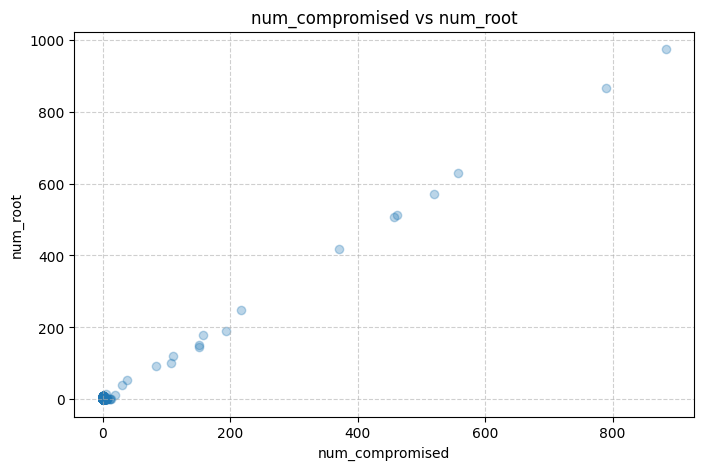

In [17]:
# ==============================================================================
# ÉTAPE 4 : Visualisation préliminaire (Nuage de points)
# ==============================================================================
plt.figure(figsize=(8, 5))
plt.scatter(df[meilleure_colonne_x], df[meilleure_colonne_y], alpha=0.3)
plt.xlabel(meilleure_colonne_x)
plt.ylabel(meilleure_colonne_y)
plt.title(f"{meilleure_colonne_x} vs {meilleure_colonne_y}")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

In [18]:
# ==============================================================================
# ÉTAPE 5 : Définition des variables X et y
# ==============================================================================
#X = df[[meilleure_colonne_x]]
#y = df[meilleure_colonne_y]

#display(X.head())
#display(y.head())

In [19]:
# ==============================================================================
# ÉTAPE 5 & 6 : Définition directe de X_train, y_train, X_test, y_test
# (Plus besoin de train_test_split si on a deux dataset !)
# ==============================================================================
# Données d'entraînement depuis Train_data.csv
X_train = df_train[[meilleure_colonne_x]]
y_train = df_train[meilleure_colonne_y]

# Données de test depuis Test_data.csv
X_test = df_test[[meilleure_colonne_x]]
y_test = df_test[meilleure_colonne_y]

print("Données d'entraînement :", len(X_train))
print("Données de test         :", len(X_test))

display(X_train.head())
display(y_train.head())

Données d'entraînement : 25192
Données de test         : 22544


,num_compromised
0,0
1,0
2,0
3,0
4,0


,num_root
0,0
1,0
2,0
3,0
4,0


In [20]:
# ==============================================================================
# ÉTAPE 7 : Entraînement du modèle de régression linéaire
# ==============================================================================
model = LinearRegression()
model.fit(X_train, y_train)

print("Modèle entraîné avec succès.")

Modèle entraîné avec succès.


In [21]:
# ==============================================================================
# ÉTAPE 8 : Paramètres du modèle (β0 et β1)
# ==============================================================================
beta0 = model.intercept_
beta1 = model.coef_[0]

print("β0 (intercept) =", beta0)
print("β1 (pente)     =", beta1)
print(f"Équation : ŷ = {beta0:.4f} + {beta1:.4f} * x")

β0 (intercept) = -0.0014446713944823442
β1 (pente)     = 1.1028561257438676
Équation : ŷ = -0.0014 + 1.1029 * x


In [22]:
# ==============================================================================
# ÉTAPE 9 : Prédiction sur le jeu de test
# ==============================================================================
y_pred = model.predict(X_test)

resultats = pd.DataFrame({
    meilleure_colonne_x: X_test[meilleure_colonne_x].values,
    "Valeur réelle": y_test.values,
    "Valeur prédite": y_pred
})

display(resultats.head(10))

,num_compromised,Valeur réelle,Valeur prédite
0,0,0,-0.001445
1,0,0,-0.001445
2,0,0,-0.001445
3,0,0,-0.001445
4,0,0,-0.001445
5,0,0,-0.001445
6,0,0,-0.001445
7,0,0,-0.001445
8,0,0,-0.001445
9,0,0,-0.001445


In [23]:
# ==============================================================================
# ÉTAPE 10 : Calcul des résidus (Erreur de prédiction)
# ==============================================================================
resultats["Résidu"] = resultats["Valeur réelle"] - resultats["Valeur prédite"]

display(resultats.head(10))

,num_compromised,Valeur réelle,Valeur prédite,Résidu
0,0,0,-0.001445,0.001445
1,0,0,-0.001445,0.001445
2,0,0,-0.001445,0.001445
3,0,0,-0.001445,0.001445
4,0,0,-0.001445,0.001445
5,0,0,-0.001445,0.001445
6,0,0,-0.001445,0.001445
7,0,0,-0.001445,0.001445
8,0,0,-0.001445,0.001445
9,0,0,-0.001445,0.001445


In [24]:
# ==============================================================================
# ÉTAPE 11 : Évaluation des métriques (MAE, MSE, R²)
# ==============================================================================
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"R²   : {r2:.4f}")

MAE  : 0.0344
MSE  : 0.5217
R²   : 0.9919


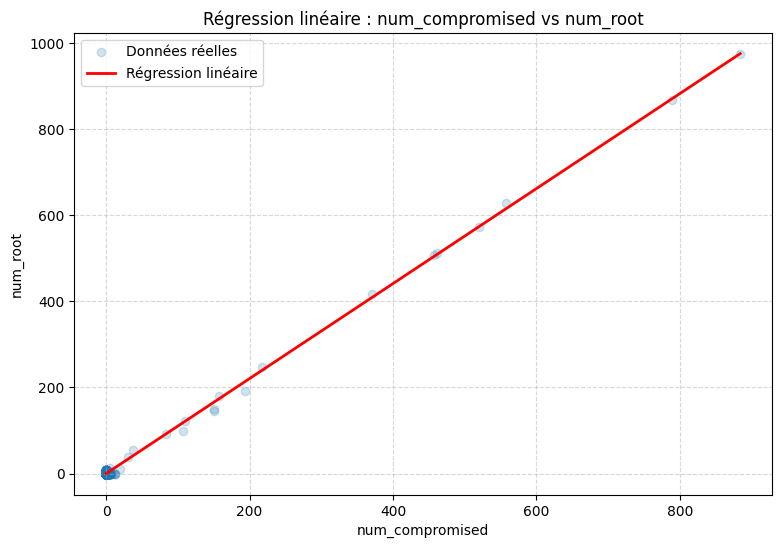

In [25]:
# ==============================================================================
# ÉTAPE 12 : Tracé de la droite de régression linéaire
# ==============================================================================
X_plot = pd.DataFrame({
    meilleure_colonne_x: np.linspace(
        df[meilleure_colonne_x].min(),
        df[meilleure_colonne_x].max(),
        100
    )
})

y_plot = model.predict(X_plot)

plt.figure(figsize=(9, 6))
plt.scatter(df[meilleure_colonne_x], df[meilleure_colonne_y], alpha=0.2, label="Données réelles")
plt.plot(X_plot[meilleure_colonne_x], y_plot, color="red", linewidth=2, label="Régression linéaire")
plt.xlabel(meilleure_colonne_x)
plt.ylabel(meilleure_colonne_y)
plt.title(f"Régression linéaire : {meilleure_colonne_x} vs {meilleure_colonne_y}")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [26]:
# ==============================================================================
# ÉTAPE 13 : Test d'une nouvelle observation et détection d'anomalie
# ==============================================================================
# Exemple avec la médiane de la variable X
valeur_test = float(df[meilleure_colonne_x].median())
nouvelle_donnee = pd.DataFrame({
    meilleure_colonne_x: [valeur_test]
})

valeur_attendue = model.predict(nouvelle_donnee)[0]
print(f"Pour {meilleure_colonne_x} = {valeur_test}, la valeur attendue est : {valeur_attendue:.2f}")

# Simulation d'une valeur observée
valeur_observee = valeur_attendue * 1.5  # valeur simulée
residu_obs = valeur_observee - valeur_attendue

print("Valeur attendue :", round(valeur_attendue, 2))
print("Valeur observée :", round(valeur_observee, 2))
print("Résidu          :", round(residu_obs, 2))

seuil = 3 * mae   # seuil adaptatif basé sur 3x l'erreur absolue moyenne (MAE)

if abs(residu_obs) > seuil:
    print("⚠️ Écart important : observation à investiguer.")
else:
    print("✓ Écart dans la plage définie.")

print("\nAttention : un écart important ne signifie pas automatiquement qu'il s'agit d'une cyberattaque.")

Pour num_compromised = 0.0, la valeur attendue est : -0.00
Valeur attendue : -0.0
Valeur observée : -0.0
Résidu          : -0.0
✓ Écart dans la plage définie.

Attention : un écart important ne signifie pas automatiquement qu'il s'agit d'une cyberattaque.
